In [2]:
import pandas as pd
import numpy as np

np.random.seed(42)

dates = pd.date_range('2024-01-01', periods=730)

data = pd.DataFrame({
    'Date': dates,
    'Page_Views': 2000 + np.arange(730) * 2 +
                  300 * np.sin(2 * np.pi * np.arange(730) / 7) +
                  np.random.normal(0, 150, 730),
    'Unique_Visitors': np.random.randint(500, 2000, 730),
    'Bounce_Rate': np.random.uniform(25, 75, 730)
})

data['Page_Views'] = data['Page_Views'].clip(lower=0).astype(int)
data.to_csv('/content/website_traffic.csv', index=False)

print(data.head())
print("Dataset shape:", data.shape)

        Date  Page_Views  Unique_Visitors  Bounce_Rate
0 2024-01-01        2074              574    26.498679
1 2024-01-02        2215             1337    40.396497
2 2024-01-03        2393             1669    60.234038
3 2024-01-04        2364              627    35.092673
4 2024-01-05        1842              541    58.671622
Dataset shape: (730, 4)


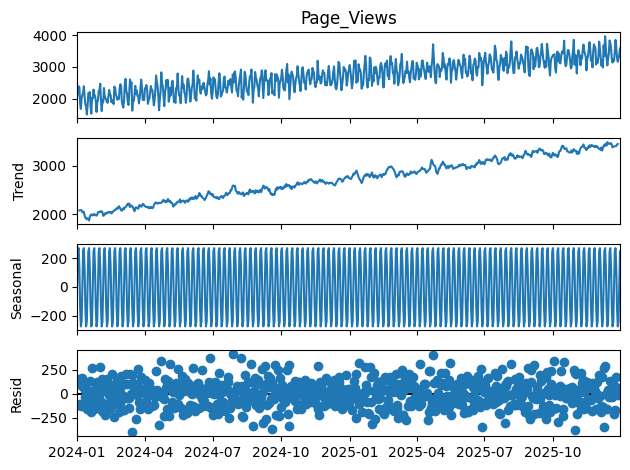

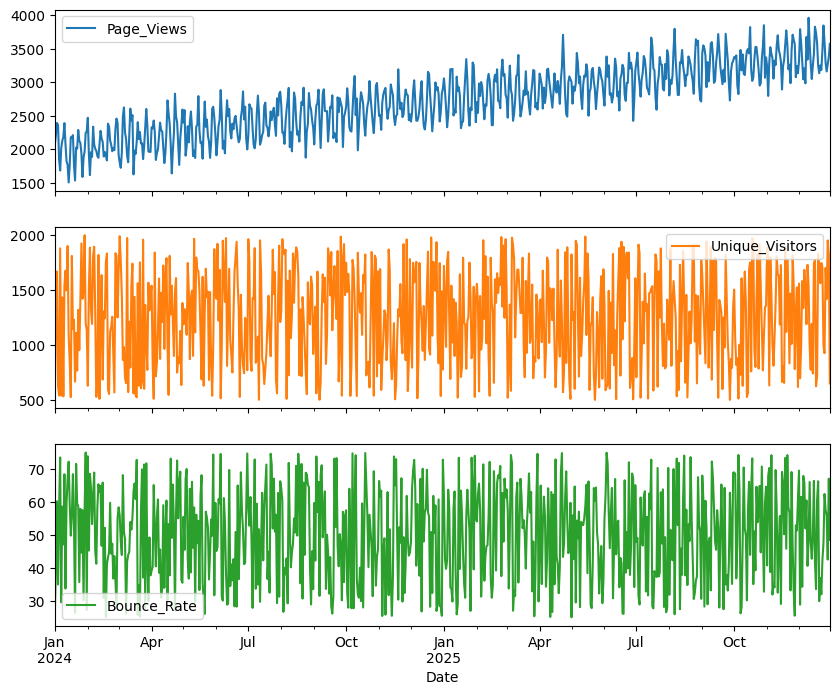

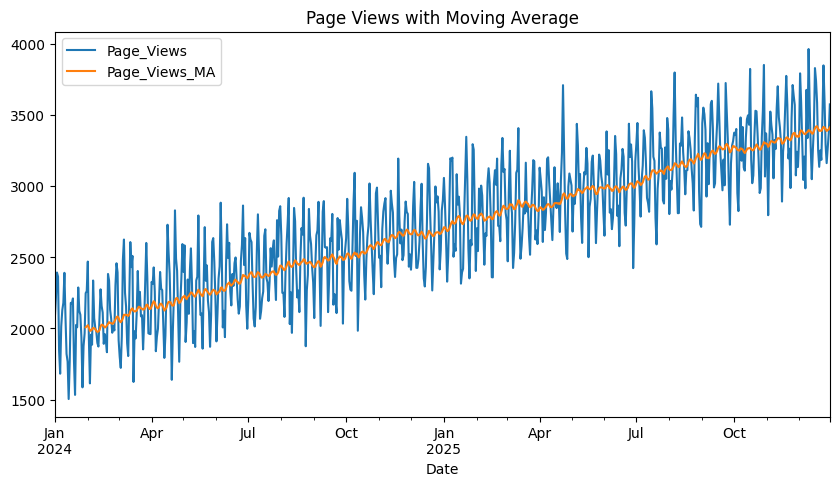

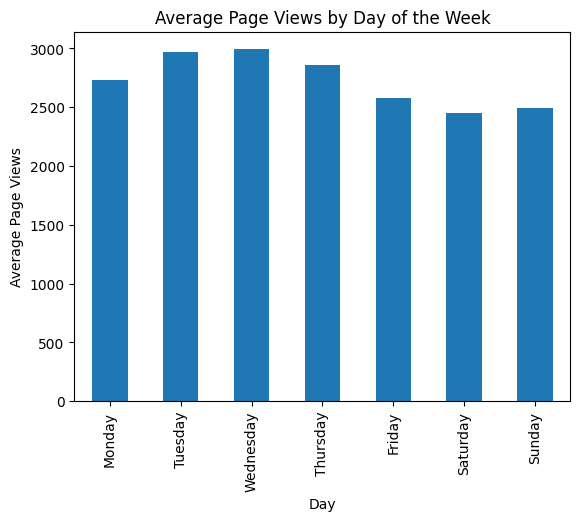

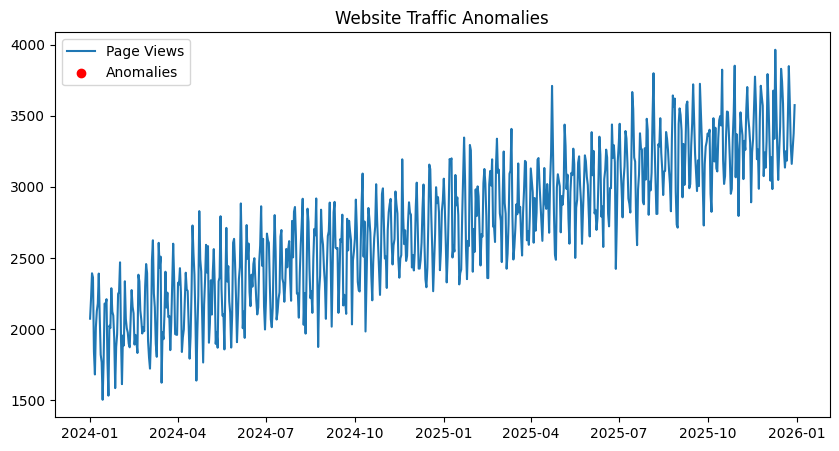

Number of anomalies: 0


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

# Load and clean data
data = pd.read_csv(
    '/content/website_traffic.csv',
    parse_dates=['Date'],
    index_col='Date'
)

data = data.sort_index()
data = data.interpolate(method='time')

# Time Series Decomposition
decomposition = seasonal_decompose(
    data['Page_Views'],
    model='additive',
    period=7
)

decomposition.plot()
plt.show()

# Plot website traffic
data[['Page_Views', 'Unique_Visitors', 'Bounce_Rate']].plot(
    subplots=True, figsize=(10, 8)
)
plt.show()

# Moving Average
data['Page_Views_MA'] = data['Page_Views'].rolling(window=30).mean()

data[['Page_Views', 'Page_Views_MA']].plot(figsize=(10, 5))
plt.title('Page Views with Moving Average')
plt.show()

# Seasonal Plot: Average traffic by day of the week
data['Day'] = data.index.day_name()

data.groupby('Day')['Page_Views'].mean().reindex([
    'Monday', 'Tuesday', 'Wednesday', 'Thursday',
    'Friday', 'Saturday', 'Sunday'
]).plot(kind='bar')

plt.title('Average Page Views by Day of the Week')
plt.ylabel('Average Page Views')
plt.show()

# Anomaly Detection using Z-score
data['Page_Views_Z'] = (
    (data['Page_Views'] - data['Page_Views'].mean())
    / data['Page_Views'].std()
)

anomalies = data[data['Page_Views_Z'].abs() > 3]

plt.figure(figsize=(10, 5))
plt.plot(data.index, data['Page_Views'], label='Page Views')
plt.scatter(
    anomalies.index,
    anomalies['Page_Views'],
    color='red',
    label='Anomalies'
)
plt.title('Website Traffic Anomalies')
plt.legend()
plt.show()

print("Number of anomalies:", len(anomalies))